# Milestone 2 — safe-haven tests and nonlinear modeling

Does Gold behave defensively during macro-financial stress, and does Bitcoin look anything like it?

66th-percentile stress flags, the 55-predictor matrix, regime returns / volatility / correlations, event windows, then Models E, F, and G. Chronological splits only. Targets are shifted before the cut.


## Setup


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    roc_auc_score, mean_squared_error, mean_absolute_error, r2_score,
)
from xgboost import XGBClassifier, XGBRegressor
sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(42)
HERE = Path.cwd()
REPO_ROOT = HERE if (HERE / "src" / "macro_stress").exists() else HERE.parent
DATA_PATH = REPO_ROOT / "data" / "Global_Market_Stress_and_Liquidity_Regimes.csv"
FIG_DIR = REPO_ROOT / "figures" / "notebook"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.is_file():
    raise SystemExit("Put the Kaggle CSV at data/Global_Market_Stress_and_Liquidity_Regimes.csv")
TEST_SIZE = 0.2
LAGS = [1, 3, 5]
N_BOOT = 1000
print("DATA_PATH:", DATA_PATH)


DATA_PATH: /Users/offamacbook/Projects/macro-asset-stress-modeling/data/Global_Market_Stress_and_Liquidity_Regimes.csv


## Load, log returns, Gold 30-day vol


In [2]:
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
df["gold_ret"] = np.log(df["Gold"]).diff()
df["spy_ret"] = np.log(df["Equities_US"]).diff()
df["btc_ret"] = np.log(df["Crypto_Bitcoin"]).diff()
df["Gold_Rolling_Vol_30d"] = df["gold_ret"].rolling(30).std() * np.sqrt(252)
print("Shape:", df.shape, "  Dates:", df["Date"].min().date(), "->", df["Date"].max().date())


Shape: (4150, 22)   Dates: 2014-10-17 -> 2026-02-25


## 66th-percentile stress regimes


In [3]:
def regime_from_quantile(s, q=0.66):
    thr = s.quantile(q)
    return (s >= thr).astype(int), float(thr)
df["stress_hys"], thr_hys = regime_from_quantile(df["High_Yield_Spread"])
df["stress_fsi"], thr_fsi = regime_from_quantile(df["Financial_Stress_Index"])
df["stress_vix"], thr_vix = regime_from_quantile(df["Volatility_Index"])
df["stress_any"] = ((df["stress_hys"] + df["stress_fsi"] + df["stress_vix"]) >= 1).astype(int)
df["stress_all"] = ((df["stress_hys"] + df["stress_fsi"] + df["stress_vix"]) == 3).astype(int)
REGIMES = ["stress_hys", "stress_fsi", "stress_vix", "stress_any", "stress_all"]
print("thresholds: HYS", round(thr_hys, 3), "FSI", round(thr_fsi, 3), "VIX", round(thr_vix, 3))
display(pd.DataFrame({"regime": REGIMES, "share": [df[r].mean() for r in REGIMES],
                      "n_high": [int(df[r].sum()) for r in REGIMES]}).round(4))


thresholds: HYS 4.4 FSI -0.172 VIX 19.06


,regime,share,n_high
0,stress_hys,0.3417,1418
1,stress_fsi,0.3407,1414
2,stress_vix,0.3402,1412
3,stress_any,0.5631,2337
4,stress_all,0.1434,595


## 55-feature matrix


In [4]:
MACRO_LEVELS = [
    "Volatility_Index", "Yield_Curve_Spread", "High_Yield_Spread",
    "Financial_Stress_Index", "SPY_Drawdown", "Stock_Bond_Corr_90d",
    "SPY_RSI_14", "GLD_RSI_14",
]
VOL_LEVELS = ["SPY_Rolling_Vol_30d", "BTC_Rolling_Vol_30d", "Gold_Rolling_Vol_30d"]
RET_COLS = ["gold_ret", "spy_ret", "btc_ret"]
feat = pd.DataFrame(index=df.index)
feat["Date"] = df["Date"]
for c in MACRO_LEVELS + VOL_LEVELS:
    feat[c] = df[c]
    for L in LAGS:
        feat[f"{c}_lag{L}"] = df[c].shift(L)
for c in RET_COLS:
    for L in LAGS:
        feat[f"{c}_lag{L}"] = df[c].shift(L)
feat["stress_hys_t"] = df["stress_hys"]
feat["stress_any_t"] = df["stress_any"]
for col in RET_COLS:
    feat[col] = df[col]
feat["stress_hys"] = df["stress_hys"]
feat["stress_any"] = df["stress_any"]
EXCLUDE = ["Date"] + RET_COLS + ["stress_hys", "stress_any"]
FEATURE_COLS = [c for c in feat.columns if c not in EXCLUDE]
print("Feature matrix:", feat.shape, "predictors:", len(FEATURE_COLS))
assert len(FEATURE_COLS) == 55
assert "stress_hys_t" in FEATURE_COLS and "stress_any_t" in FEATURE_COLS

def chrono_split(data, feature_cols, target, test_size=TEST_SIZE):
    aligned = data.loc[target.dropna().index].copy()
    aligned = aligned.dropna(subset=feature_cols)
    y = target.loc[aligned.index]
    n_test = max(1, int(len(aligned) * test_size))
    split_idx = len(aligned) - n_test
    X_tr = aligned.iloc[:split_idx][feature_cols]
    X_te = aligned.iloc[split_idx:][feature_cols]
    y_tr = y.iloc[:split_idx]
    y_te = y.iloc[split_idx:]
    d_tr = aligned.iloc[:split_idx]["Date"]
    d_te = aligned.iloc[split_idx:]["Date"]
    assert d_tr.max() < d_te.min()
    return X_tr, X_te, y_tr, y_te, d_tr, d_te

target_E = (df["gold_ret"].shift(-1) > df["spy_ret"].shift(-1)).astype(float)
target_E[df["gold_ret"].shift(-1).isna() | df["spy_ret"].shift(-1).isna()] = np.nan
target_G_hys = df["stress_hys"].shift(-5)
target_G_any = df["stress_any"].shift(-5)
print("Targets ready.")


Feature matrix: (4150, 61) predictors: 55
Targets ready.


## Regime mean returns and bootstrap CI on Gold-SPY widening


,regime,gold_high,spy_high,btc_high,delta_Gold_minus_SPY,CI_lo,CI_hi,CI_excludes_zero
0,stress_hys,0.00025,0.00003,0.00052,0.00038,-0.00049,0.00122,False
1,stress_fsi,0.00036,0.00046,-0.00003,-0.00012,-0.00099,0.00070,False
2,stress_vix,0.00068,-0.00092,-0.00008,0.00247,0.00153,0.00332,True
3,stress_any,0.00028,-0.00011,0.00008,0.00096,0.00023,0.00166,True
4,stress_all,0.00095,-0.00067,0.00025,0.00191,0.00036,0.00347,True


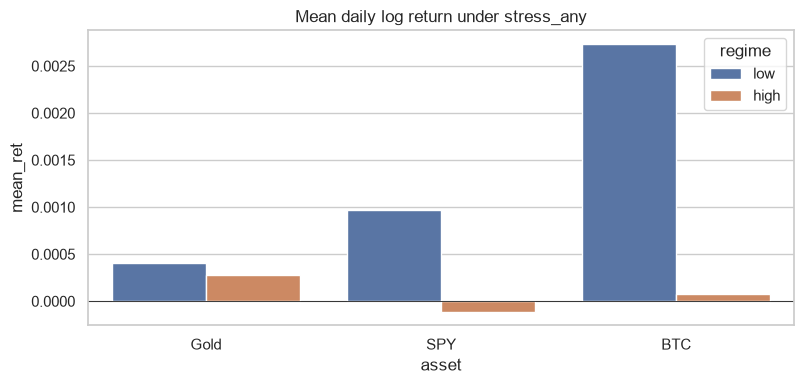

In [5]:
def bootstrap_diff_ci(d_hi, d_lo, n_boot=N_BOOT, seed=42):
    rng = np.random.default_rng(seed)
    a = np.asarray(pd.Series(d_hi).dropna())
    b = np.asarray(pd.Series(d_lo).dropna())
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        diffs[i] = rng.choice(a, size=len(a), replace=True).mean() - rng.choice(b, size=len(b), replace=True).mean()
    lo, hi = np.quantile(diffs, [0.025, 0.975])
    return float(a.mean() - b.mean()), float(lo), float(hi)
spread = df["gold_ret"] - df["spy_ret"]
rows = []
for reg in REGIMES:
    hi = df[reg] == 1
    lo = df[reg] == 0
    delta, ci_lo, ci_hi = bootstrap_diff_ci(spread[hi], spread[lo])
    rows.append({
        "regime": reg,
        "gold_high": float(df.loc[hi, "gold_ret"].mean()),
        "spy_high": float(df.loc[hi, "spy_ret"].mean()),
        "btc_high": float(df.loc[hi, "btc_ret"].mean()),
        "delta_Gold_minus_SPY": delta, "CI_lo": ci_lo, "CI_hi": ci_hi,
        "CI_excludes_zero": (ci_lo > 0) or (ci_hi < 0),
    })
ret_tbl = pd.DataFrame(rows)
display(ret_tbl.round(5))
bar = pd.DataFrame({
    "asset": ["Gold", "SPY", "BTC"] * 2,
    "regime": ["low"] * 3 + ["high"] * 3,
    "mean_ret": [
        df.loc[df["stress_any"] == 0, "gold_ret"].mean(),
        df.loc[df["stress_any"] == 0, "spy_ret"].mean(),
        df.loc[df["stress_any"] == 0, "btc_ret"].mean(),
        df.loc[df["stress_any"] == 1, "gold_ret"].mean(),
        df.loc[df["stress_any"] == 1, "spy_ret"].mean(),
        df.loc[df["stress_any"] == 1, "btc_ret"].mean(),
    ],
})
fig, ax = plt.subplots(figsize=(8.2, 4.0))
sns.barplot(data=bar, x="asset", y="mean_ret", hue="regime", ax=ax)
ax.axhline(0, color="k", lw=0.6)
ax.set_title("Mean daily log return under stress_any")
plt.tight_layout()
plt.savefig(FIG_DIR / "m2_returns_by_regime.png", dpi=140, bbox_inches="tight")
plt.show()


## Volatility by regime + Welch tests


,asset,vol_low,vol_high,pct_change,Welch_t,p
0,Gold,0.1040,0.1298,0.2484,17.1109,0.0000
1,SPY,0.0853,0.1521,0.7821,32.0353,0.0000
2,BTC,0.6079,0.6095,0.0025,0.1774,0.8592


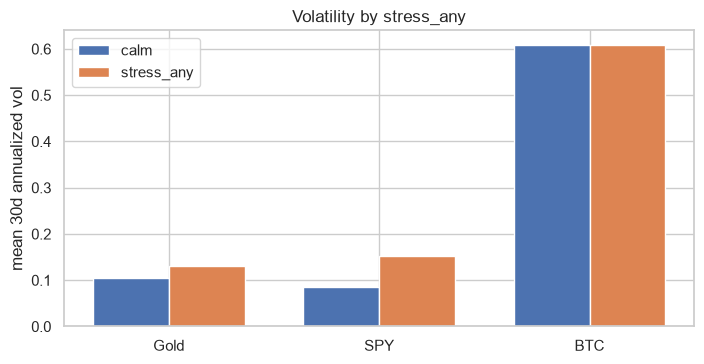

In [6]:
vol_cols = {"Gold": "Gold_Rolling_Vol_30d", "SPY": "SPY_Rolling_Vol_30d", "BTC": "BTC_Rolling_Vol_30d"}
vol_rows = []
for name, col in vol_cols.items():
    hi = df.loc[df["stress_any"] == 1, col].dropna()
    lo = df.loc[df["stress_any"] == 0, col].dropna()
    t, p = stats.ttest_ind(hi, lo, equal_var=False)
    vol_rows.append({"asset": name, "vol_low": float(lo.mean()), "vol_high": float(hi.mean()),
                     "pct_change": float(hi.mean() / lo.mean() - 1.0), "Welch_t": float(t), "p": float(p)})
vol_tbl = pd.DataFrame(vol_rows)
display(vol_tbl.round(4))
fig, ax = plt.subplots(figsize=(7.2, 3.8))
x = np.arange(3)
ax.bar(x - 0.18, vol_tbl["vol_low"], 0.36, label="calm")
ax.bar(x + 0.18, vol_tbl["vol_high"], 0.36, label="stress_any")
ax.set_xticks(x, vol_tbl["asset"])
ax.set_ylabel("mean 30d annualized vol")
ax.set_title("Volatility by stress_any")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "m2_vol_by_regime.png", dpi=140, bbox_inches="tight")
plt.show()


## 60-day rolling Gold-SPY and Gold-BTC correlation, stress_any shaded


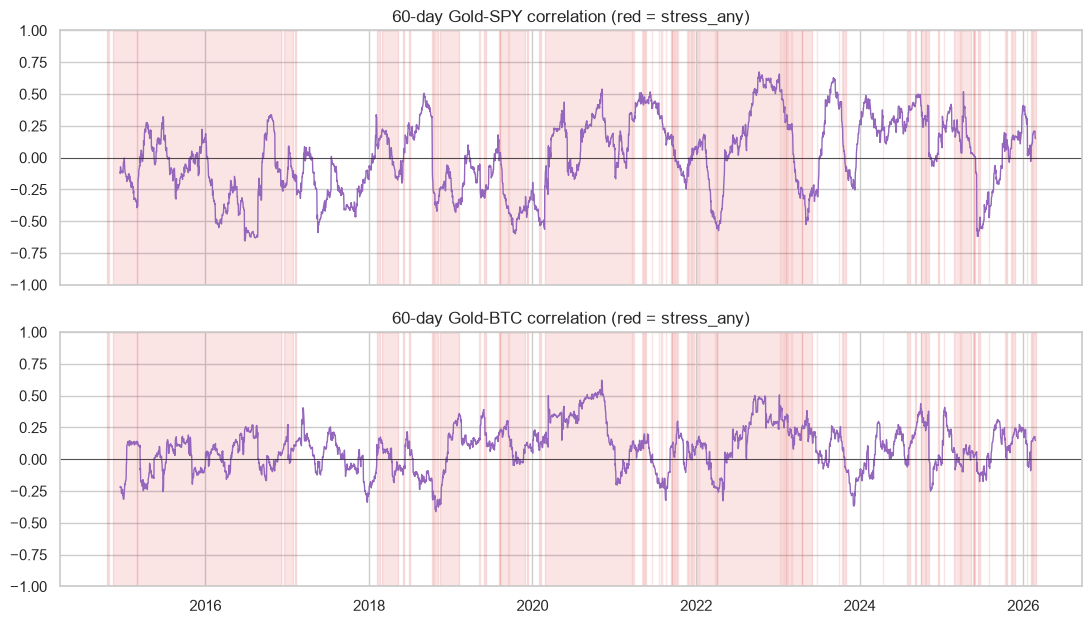

stress_hys Gold-SPY 60d mean calm/stress: 0.016 -0.003
stress_fsi Gold-SPY 60d mean calm/stress: 0.045 -0.059
stress_vix Gold-SPY 60d mean calm/stress: -0.032 0.089
stress_any Gold-SPY 60d mean calm/stress: 0.034 -0.01
stress_all Gold-SPY 60d mean calm/stress: -0.002 0.078


In [7]:
roll = df.copy()
roll["gold_spy_60"] = roll["gold_ret"].rolling(60).corr(roll["spy_ret"])
roll["gold_btc_60"] = roll["gold_ret"].rolling(60).corr(roll["btc_ret"])
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
for ax, col, title in [
    (axes[0], "gold_spy_60", "60-day Gold-SPY correlation"),
    (axes[1], "gold_btc_60", "60-day Gold-BTC correlation"),
]:
    ax.plot(roll["Date"], roll[col], color="tab:purple", lw=1.0)
    ax.fill_between(roll["Date"], -1, 1, where=roll["stress_any"] == 1,
                    color="tab:red", alpha=0.12, transform=ax.get_xaxis_transform())
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylim(-1, 1)
    ax.set_title(title + " (red = stress_any)")
plt.tight_layout()
plt.savefig(FIG_DIR / "m2_rolling_corr.png", dpi=140, bbox_inches="tight")
plt.show()
for flag in REGIMES:
    c = roll["gold_ret"].rolling(60).corr(roll["spy_ret"])
    print(flag, "Gold-SPY 60d mean calm/stress:",
          round(float(c.loc[roll[flag] == 0].mean()), 3),
          round(float(c.loc[roll[flag] == 1].mean()), 3))


## Event windows\n\nCOVID: 2020-02-15 to 2020-04-30. Inflation/rates: 2022-06-01 to 2022-10-31. Banking: 2023-03-01 to 2023-04-30.


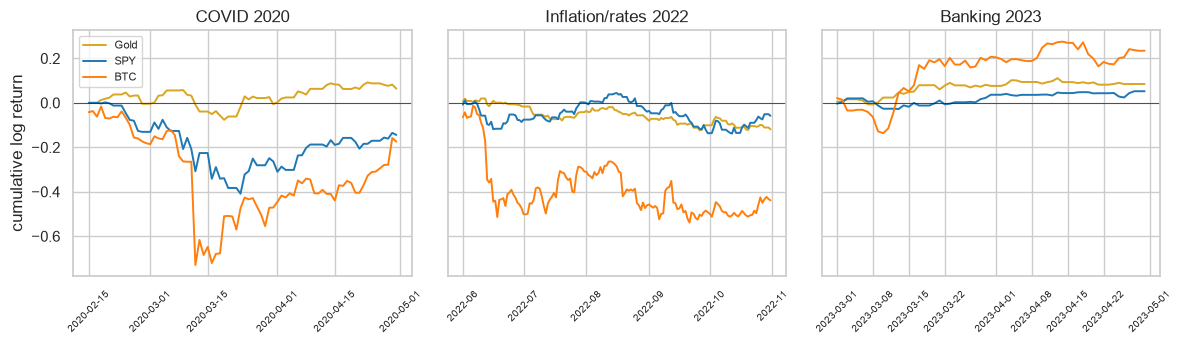

,event,n,Gold,SPY,BTC
0,COVID 2020,76,0.0637,-0.1445,-0.1748
1,Inflation/rates 2022,153,-0.1192,-0.0585,-0.4390
2,Banking 2023,61,0.0848,0.0523,0.2346


In [8]:
EVENTS = {
    "COVID 2020": ("2020-02-15", "2020-04-30"),
    "Inflation/rates 2022": ("2022-06-01", "2022-10-31"),
    "Banking 2023": ("2023-03-01", "2023-04-30"),
}
ev_rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (name, (start, end)) in zip(axes, EVENTS.items()):
    w = df.loc[(df["Date"] >= start) & (df["Date"] <= end)].copy()
    for col, color, lab in [("gold_ret", "goldenrod", "Gold"),
                            ("spy_ret", "tab:blue", "SPY"),
                            ("btc_ret", "tab:orange", "BTC")]:
        ax.plot(w["Date"], w[col].cumsum(), color=color, lw=1.4, label=lab)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(name)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    ev_rows.append({"event": name, "n": int(len(w)),
                    "Gold": float(w["gold_ret"].sum()),
                    "SPY": float(w["spy_ret"].sum()),
                    "BTC": float(w["btc_ret"].sum())})
axes[0].legend(fontsize=8)
axes[0].set_ylabel("cumulative log return")
plt.tight_layout()
plt.savefig(FIG_DIR / "m2_event_windows.png", dpi=140, bbox_inches="tight")
plt.show()
display(pd.DataFrame(ev_rows).round(4))


## Model E: will Gold beat SPY tomorrow?


In [9]:
X_tr_E, X_te_E, y_tr_E, y_te_E, d_tr_E, d_te_E = chrono_split(feat, FEATURE_COLS, target_E)
y_tr_E = y_tr_E.astype(int); y_te_E = y_te_E.astype(int)
print("Train:", len(y_tr_E), pd.Timestamp(d_tr_E.iloc[0]).date(), "->", pd.Timestamp(d_tr_E.iloc[-1]).date())
print("Test :", len(y_te_E), pd.Timestamp(d_te_E.iloc[0]).date(), "->", pd.Timestamp(d_te_E.iloc[-1]).date())
print("Test Gold>SPY rate:", round(float(y_te_E.mean()), 3))

def clf_metrics(name, y_true, y_pred, y_prob):
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced": balanced_accuracy_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.5}

maj = int(pd.Series(y_tr_E).mode().iloc[0])
vix_thr = float(X_tr_E["Volatility_Index"].median())
vix_score = X_te_E["Volatility_Index"].to_numpy()
vix_pred = (vix_score > vix_thr).astype(int)
logit = Pipeline([("sc", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))]).fit(X_tr_E, y_tr_E)
logit_prob = logit.predict_proba(X_te_E)[:, 1]
xgb = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
                    subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                    random_state=42, n_jobs=-1, verbosity=0).fit(X_tr_E, y_tr_E)
xgb_prob = xgb.predict_proba(X_te_E)[:, 1]
e_tbl = pd.DataFrame([
    clf_metrics("Majority", y_te_E, np.full(len(y_te_E), maj), np.full(len(y_te_E), 0.5)),
    clf_metrics("VIX > train median", y_te_E, vix_pred, vix_score),
    clf_metrics("Logistic (balanced)", y_te_E, (logit_prob >= 0.5).astype(int), logit_prob),
    clf_metrics("XGBoost", y_te_E, (xgb_prob >= 0.5).astype(int), xgb_prob),
]).set_index("model")
display(e_tbl.round(4))
imp = pd.Series(xgb.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False).head(10)
display(imp.round(4).to_frame("gain"))


Train: 3292 2014-11-21 -> 2023-11-25
Test : 822 2023-11-26 -> 2026-02-24
Test Gold>SPY rate: 0.383


,accuracy,balanced,f1,roc_auc
model,,,,
Majority,0.6168,0.5000,0.0000,0.5000
VIX > train median,0.5365,0.5125,0.4038,0.5040
Logistic (balanced),0.5766,0.5883,0.5360,0.6091
XGBoost,0.6436,0.5932,0.4482,0.6773


,gain
spy_ret_lag3,0.0339
spy_ret_lag1,0.0322
gold_ret_lag1,0.0280
gold_ret_lag3,0.0259
BTC_Rolling_Vol_30d_lag1,0.0209
Stock_Bond_Corr_90d_lag1,0.0206
BTC_Rolling_Vol_30d_lag3,0.0205
Volatility_Index_lag3,0.0202
Stock_Bond_Corr_90d_lag5,0.0199
SPY_Rolling_Vol_30d_lag5,0.0193


## Model F: Persistence / Ridge / XGBoost on SPY vol, BTC vol, VIX at h=1 and h=5


In [10]:
def chrono_reg(data, feature_cols, target, persist_col):
    aligned = data.loc[target.dropna().index].copy()
    aligned = aligned.dropna(subset=feature_cols + [persist_col])
    y = target.loc[aligned.index]
    n_test = max(1, int(len(aligned) * TEST_SIZE))
    split_idx = len(aligned) - n_test
    tr, te = aligned.iloc[:split_idx], aligned.iloc[split_idx:]
    y_tr, y_te = y.iloc[:split_idx], y.iloc[split_idx:]
    persist = te[persist_col].to_numpy()
    ridge = Pipeline([("sc", StandardScaler()), ("ridge", Ridge(alpha=1.0))])
    ridge.fit(tr[feature_cols], y_tr)
    xgbr = XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05,
                        subsample=0.9, colsample_bytree=0.9,
                        random_state=42, n_jobs=-1, verbosity=0).fit(tr[feature_cols], y_tr)
    rows = []
    for name, hat in [("Persistence", persist),
                      ("Ridge", ridge.predict(te[feature_cols])),
                      ("XGBoost", xgbr.predict(te[feature_cols]))]:
        rows.append({"model": name,
                     "RMSE": float(np.sqrt(mean_squared_error(y_te, hat))),
                     "MAE": float(mean_absolute_error(y_te, hat)),
                     "R2": float(r2_score(y_te, hat))})
    return pd.DataFrame(rows)
tasks = [
    ("SPY 30d vol h=1", df["SPY_Rolling_Vol_30d"].shift(-1), "SPY_Rolling_Vol_30d"),
    ("SPY 30d vol h=5", df["SPY_Rolling_Vol_30d"].shift(-5), "SPY_Rolling_Vol_30d"),
    ("BTC 30d vol h=1", df["BTC_Rolling_Vol_30d"].shift(-1), "BTC_Rolling_Vol_30d"),
    ("BTC 30d vol h=5", df["BTC_Rolling_Vol_30d"].shift(-5), "BTC_Rolling_Vol_30d"),
    ("VIX h=1", df["Volatility_Index"].shift(-1), "Volatility_Index"),
    ("VIX h=5", df["Volatility_Index"].shift(-5), "Volatility_Index"),
]
for label, tgt, persist_col in tasks:
    tbl = chrono_reg(feat, FEATURE_COLS, tgt, persist_col)
    tbl.insert(0, "task", label)
    print(label)
    display(tbl.round(4))


SPY 30d vol h=1


,task,model,RMSE,MAE,R2
0,SPY 30d vol h=1,Persistence,0.0099,0.0035,0.9786
1,SPY 30d vol h=1,Ridge,0.0097,0.0043,0.9796
2,SPY 30d vol h=1,XGBoost,0.0213,0.0077,0.9017


SPY 30d vol h=5


,task,model,RMSE,MAE,R2
0,SPY 30d vol h=5,Persistence,0.0248,0.0123,0.8670
1,SPY 30d vol h=5,Ridge,0.0210,0.0125,0.9046
2,SPY 30d vol h=5,XGBoost,0.0318,0.0176,0.7811


BTC 30d vol h=1


...

,task,model,RMSE,MAE,R2
0,BTC 30d vol h=5,Persistence,0.0608,0.0401,0.8074
1,BTC 30d vol h=5,Ridge,0.0612,0.0460,0.8045
2,BTC 30d vol h=5,XGBoost,0.0747,0.0492,0.7095


VIX h=1


,task,model,RMSE,MAE,R2
0,VIX h=1,Persistence,1.6448,0.7237,0.8729
1,VIX h=1,Ridge,1.6421,0.8491,0.8733
2,VIX h=1,XGBoost,1.9315,1.1988,0.8247


VIX h=5


,task,model,RMSE,MAE,R2
0,VIX h=5,Persistence,3.2783,1.8604,0.4950
1,VIX h=5,Ridge,3.2904,2.0936,0.4912
2,VIX h=5,XGBoost,5.4466,4.3942,-0.3940


## Model G (M2): stress_hys.shift(-5) shows the rare-event problem. Milestone 3 retargets to stress_any.


In [11]:
X_tr_G, X_te_G, y_tr_G, y_te_G, d_tr_G, d_te_G = chrono_split(feat, FEATURE_COLS, target_G_hys)
y_tr_G = y_tr_G.astype(int); y_te_G = y_te_G.astype(int)
print("Test positive rate for stress_hys h=5:", round(float(y_te_G.mean()), 4))
maj = int(pd.Series(y_tr_G).mode().iloc[0])
persist = X_te_G["stress_hys_t"].astype(int).to_numpy()
logit_g = Pipeline([("sc", StandardScaler()),
                    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))]).fit(X_tr_G, y_tr_G)
xgb_g = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
                      subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                      random_state=42, n_jobs=-1, verbosity=0).fit(X_tr_G, y_tr_G)
g_tbl = pd.DataFrame([
    clf_metrics("Majority", y_te_G, np.full(len(y_te_G), maj), np.full(len(y_te_G), 0.5)),
    clf_metrics("Regime persists", y_te_G, persist, persist.astype(float)),
    clf_metrics("Logistic (balanced)", y_te_G, logit_g.predict(X_te_G), logit_g.predict_proba(X_te_G)[:, 1]),
    clf_metrics("XGBoost", y_te_G, xgb_g.predict(X_te_G), xgb_g.predict_proba(X_te_G)[:, 1]),
]).set_index("model")
display(g_tbl.round(4))
print("Accuracy is dominated by the negative class. Notebook 03 uses stress_any.shift(-5) and PR-AUC.")


Test positive rate for stress_hys h=5: 0.0073


,accuracy,balanced,f1,roc_auc
model,,,,
Majority,0.9927,0.5000,0.0000,0.5000
Regime persists,0.9878,0.5803,0.1667,0.5803
Logistic (balanced),0.9818,0.5772,0.1176,0.9312
XGBoost,0.9842,0.5784,0.1333,0.5074


Accuracy is dominated by the negative class. Notebook 03 uses stress_any.shift(-5) and PR-AUC.


## Takeaway

Gold is a **conditional** safe haven: the Gold-SPY spread widens under VIX-style stress and in COVID, not under every definition and not in 2022 inflation/rates. Bitcoin does not look like digital gold. Model E is the modeling win; volatility still belongs to persistence / Ridge; Model G on stress_hys is too rare to trust accuracy.
